# Guided exercise: the metric memo for Kalpa Retail, and the transfer note for Rohan

*Applies all six chapters on the bank's real scores · also searched as: confusion matrix exercise, precision recall practice, threshold from costs*

**Who needs the answer.** Kavya Nair, Kalpa Retail's senior analyst, who signs off the metric memo before Marketing sees it, and Rohan Desai at Kalpa Financial Services, who wants one paragraph on why his threshold would sit somewhere else.

**The questions on the way.** What does each cell of the matrix say in Kalpa's words? What are precision, recall and F1 at the default threshold? Where does Anand's 1-in-N test put the nudge threshold? Where does Rohan's put the loan threshold, said on the same quantity?

**How to work.** Each step has one or more lines that read `= None`. Replace `None` with an expression, run the cell, and run the check cell under it: it prints PASS when you are right, NOT YET when the number is off, and TODO while the line is still `None`. The worked answer is the last cell; open it only after the memo is written.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, MUTED, LIGHT = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#EEEAFB"

# Load the day's public dataset once; later runs read the cached copy.
# UCI Bank Marketing, bank-additional-full.csv, CC BY 4.0 (Moro, Rita and Cortez, 2014).
import io, zipfile, pathlib, urllib.request
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def load_bank():
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"  # verified 28 October 2026
        outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

# The customer table on the morning of the call (Monday's columns): who the client is, how earlier campaigns went.
PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
COLS = PROFILE + HISTORY

def week_split(df, seed=42):
    """Test is sealed first (20 percent, Friday's envelope); the rest splits 75/25 into train and validation."""
    y = (df["y"] == "yes").astype(int)
    rest, test = train_test_split(df.index, test_size=0.20, stratify=y, random_state=seed)
    train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=seed)
    return df.loc[train], df.loc[val], df.loc[test]

def logistic(columns, df):
    # pandas 3 reads text as the "str" dtype, so test for numbers rather than for object.
    num = [c for c in columns if pd.api.types.is_numeric_dtype(df[c])]
    cat = [c for c in columns if c not in num]
    prep = ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))])

bank = load_bank()
train, val, test = week_split(bank)
model = logistic(COLS, bank).fit(train[COLS], (train["y"] == "yes").astype(int))
y_val = (val["y"] == "yes").astype(int).to_numpy()      # 1 = the client subscribed (a buyer)
p_val = model.predict_proba(val[COLS])[:, 1]             # the model's P(buy) for each validation client
print(f"rows {len(bank):,}; train {len(train):,}, validation {len(val):,}, test {len(test):,} (sealed until Friday)")
print(f"buyers in validation: {y_val.sum():,} of {len(y_val):,}, a base rate of {y_val.mean():.2%}")

def cells(y, p, threshold):
    """The four boxes at one threshold: act (call, nudge) when the score is at or above it."""
    act = p >= threshold
    tp = int((act & (y == 1)).sum()); fp = int((act & (y == 0)).sum())
    fn = int((~act & (y == 1)).sum()); tn = int((~act & (y == 0)).sum())
    return tp, fp, fn, tn

def step(label, value, expected, tol=0.002):
    if value is None:
        print(f"TODO     {label}: replace None above, then run this cell again")
    elif abs(float(value) - expected) <= tol * max(1, abs(expected)):
        print(f"PASS  {label} = {value}")
    else:
        print(f"NOT YET  {label} = {value}; recount from the matrix")
TP0, FP0, FN0, TN0 = cells(y_val, p_val, 0.5)
print("PASS  Monday's model is rebuilt and scored on the validation slice" if TP0 + FP0 + FN0 + TN0 == 8238 else "CHECK setup")

rows 41,188; train 24,712, validation 8,238, test 8,238 (sealed until Friday)
buyers in validation: 928 of 8,238, a base rate of 11.26%
PASS  Monday's model is rebuilt and scored on the validation slice


## Step 1: what does each cell say in Kalpa's words?

The cell below prints the matrix at the default threshold 0.5 the way scikit-learn lays it out. Read it, then fill in the four counts by name. Rows are the truth and columns the prediction, so the top-left cell is not the true positives.

In [2]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_val, (p_val >= 0.5).astype(int)))
tp = None    # nudged and bought
fp = None    # nudged, did not buy: a wasted Rs 40
fn = None    # left alone, bought: a missed Rs 1,200
tn = None    # left alone, did not buy

[[7216   94]
 [ 754  174]]


In [3]:
step("TP", tp, TP0); step("FP", fp, FP0); step("FN", fn, FN0); step("TN", tn, TN0)

TODO     TP: replace None above, then run this cell again
TODO     FP: replace None above, then run this cell again
TODO     FN: replace None above, then run this cell again
TODO     TN: replace None above, then run this cell again


## Step 2: precision, recall and F1, derived

Write each as a ratio of the counts you named. Say the sentence first: "of those we called", "of those who bought".

In [4]:
precision = None   # of those we called, the share who bought
recall = None      # of those who bought, the share we called
f1 = None          # the harmonic mean of the two
print('your values:', precision, recall, f1)

your values: None None None


In [5]:
P0 = TP0 / (TP0 + FP0); R0 = TP0 / (TP0 + FN0)
step("precision", precision, P0); step("recall", recall, R0); step("F1", f1, 2 * P0 * R0 / (P0 + R0))

TODO     precision: replace None above, then run this cell again
TODO     recall: replace None above, then run this cell again
TODO     F1: replace None above, then run this cell again


## Step 3: the nudge threshold from Anand's costs

A wasted nudge costs Rs 40 and a missed buyer about Rs 1,200. Use the 1-in-N test, then count how many of the 8,238 clients the threshold calls.

In [6]:
nudge_threshold = None   # cost of acting wrongly / (cost of acting wrongly + cost of failing to act)
called = None            # how many clients score at or above it: use (p_val >= nudge_threshold).sum()
print('your values:', nudge_threshold, called)

your values: None None


In [7]:
step("nudge threshold", nudge_threshold, 40 / 1240); step("clients called", called, int((p_val >= 40 / 1240).sum()))

TODO     nudge threshold: replace None above, then run this cell again
TODO     clients called: replace None above, then run this cell again


## Step 4 (unguided): Rohan's threshold, on the same quantity

At Kalpa Financial Services a false approval costs Rs 60,000 and a wrongful rejection Rs 3,000. Write the line as a probability of the good outcome (repays), so it can sit beside the nudge line on one axis.

In [8]:
lend_threshold = None    # lend when P(repay) is above this
print('your value:', lend_threshold)

your value: None


In [9]:
step("lend threshold on P(repay)", lend_threshold, 60000 / 63000)

TODO     lend threshold on P(repay): replace None above, then run this cell again


## Step 5: write the memo and the note

Copy this into your own notes and fill the brackets with numbers from your run.

**The metric memo, to Kavya.** Claim: we report [metric] at threshold [t], because a missed buyer costs [ratio] times a wasted nudge. Evidence: at 0.5 the model calls [n] and finds [TP] of [buyers], recall [r]; at [t] it calls [n] and finds [TP]. Caveat: at this cost ratio calling almost everyone costs within [x] percent of the model's bill, so the model's value shows under a budget. Action: rank by score and call the top [k] the budget allows.

**The transfer note, to Rohan.** In lending the dearer mistake is the approval, so the same model approves only when P(repay) is above [t], about [n] repayers in every [n + 1] approvals; Retail nudges above [t], because there the dearer mistake is the miss.

## The worked answer

Open this only after your memo is written. It recomputes every step and draws the matrix.

Step 1: TP 174, FP 94, FN 754, TN 7,216
Step 2: precision 0.649, recall 0.188, F1 0.291
Step 3: nudge above 0.032; calls 7,438 and finds 913 buyers
Step 4: lend above P(repay) 0.952, that is 20 in 21; Retail acts at the bottom of the same axis, Financial at the top


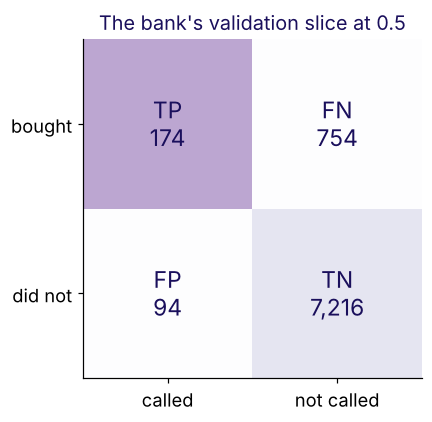

PASS  the worked answer reconciles to 8,238 clients
PASS  the two lines sit at opposite ends of the probability axis


In [10]:
TPa, FPa, FNa, TNa = cells(y_val, p_val, 0.5)
Pa, Ra = TPa / (TPa + FPa), TPa / (TPa + FNa)
print(f"Step 1: TP {TPa}, FP {FPa}, FN {FNa}, TN {TNa:,}")
print(f"Step 2: precision {Pa:.3f}, recall {Ra:.3f}, F1 {2 * Pa * Ra / (Pa + Ra):.3f}")
t_n = 40 / 1240; t_l = 60000 / 63000
print(f"Step 3: nudge above {t_n:.3f}; calls {(p_val >= t_n).sum():,} and finds {cells(y_val, p_val, t_n)[0]} buyers")
print(f"Step 4: lend above P(repay) {t_l:.3f}, that is 20 in 21; Retail acts at the bottom of the same axis, Financial at the top")
fig, ax = plt.subplots(figsize=(6.5, 4))
grid = np.array([[TPa, FNa], [FPa, TNa]])
ax.imshow([[1, 0], [0, 0.4]], cmap="Purples", alpha=0.35)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{['TP', 'FN'][j] if i == 0 else ['FP', 'TN'][j]}\n{grid[i, j]:,}", ha="center", va="center", fontsize=15, color=INK)
ax.set_xticks([0, 1]); ax.set_xticklabels(["called", "not called"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["bought", "did not"])
ax.set_title("The bank's validation slice at 0.5", color=INK); plt.tight_layout(); plt.show()
print("PASS  the worked answer reconciles to 8,238 clients" if grid.sum() == 8238 else "CHECK total")
print("PASS  the two lines sit at opposite ends of the probability axis" if t_n < 0.05 and t_l > 0.95 else "CHECK lines")